# 1.Importing Phase

**Dataset:** [Ames Housing Dataset](https://www.kaggle.com/datasets/shashanknecrothapa/ames-housing-dataset) — 2,930 rows, 82 features

In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.linear_model import LinearRegression , Ridge,LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import kagglehub
import os

path = kagglehub.dataset_download(
    "shashanknecrothapa/ames-housing-dataset"
)

print("Path to dataset files:", path)
print(os.listdir(path))
from xgboost import XGBRegressor

Path to dataset files: C:\Users\mohamed zizo\.cache\kagglehub\datasets\shashanknecrothapa\ames-housing-dataset\versions\1
['AmesHousing.csv']


In [30]:
df = pd.read_csv(os.path.join(path, "AmesHousing.csv"))
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


# 2.Initial Inspection

In [31]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [32]:
df.shape

(2930, 82)

In [33]:
df.describe()

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


# 3.Data Cleaning and EDA

In [34]:
df.columns = df.columns.str.lower().str.replace(' ', '_').str.strip()
df.columns

Index(['order', 'pid', 'ms_subclass', 'ms_zoning', 'lot_frontage', 'lot_area',
       'street', 'alley', 'lot_shape', 'land_contour', 'utilities',
       'lot_config', 'land_slope', 'neighborhood', 'condition_1',
       'condition_2', 'bldg_type', 'house_style', 'overall_qual',
       'overall_cond', 'year_built', 'year_remod/add', 'roof_style',
       'roof_matl', 'exterior_1st', 'exterior_2nd', 'mas_vnr_type',
       'mas_vnr_area', 'exter_qual', 'exter_cond', 'foundation', 'bsmt_qual',
       'bsmt_cond', 'bsmt_exposure', 'bsmtfin_type_1', 'bsmtfin_sf_1',
       'bsmtfin_type_2', 'bsmtfin_sf_2', 'bsmt_unf_sf', 'total_bsmt_sf',
       'heating', 'heating_qc', 'central_air', 'electrical', '1st_flr_sf',
       '2nd_flr_sf', 'low_qual_fin_sf', 'gr_liv_area', 'bsmt_full_bath',
       'bsmt_half_bath', 'full_bath', 'half_bath', 'bedroom_abvgr',
       'kitchen_abvgr', 'kitchen_qual', 'totrms_abvgrd', 'functional',
       'fireplaces', 'fireplace_qu', 'garage_type', 'garage_yr_blt',
      

In [35]:
df['mas_vnr_type'].value_counts()

mas_vnr_type
BrkFace    880
Stone      249
BrkCmn      25
CBlock       1
Name: count, dtype: int64

In [36]:
df['mas_vnr_type'] = df['mas_vnr_type'].fillna('None')

df['mas_vnr_area'] = df['mas_vnr_area'].fillna(0)

In [37]:
df['has_fence'] = df['fence'].notna().astype(int)
df['has_fence'].value_counts()
df.groupby('has_fence')['saleprice'].median()

df['has_alley'] = df['alley'].notna().astype(int)
df['has_alley'].value_counts()
df.groupby('has_alley')['saleprice'].median()


df = df.drop(columns=['pool_qc', 'has_pool', 'alley', 'has_alley', 'misc_feature','fence'], errors='ignore')

In [38]:
df.duplicated().sum()

np.int64(0)

In [39]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=[object]).columns.tolist()

C:\Users\mohamed zizo\AppData\Local\Temp\ipykernel_32448\2399741835.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=[object]).columns.tolist()


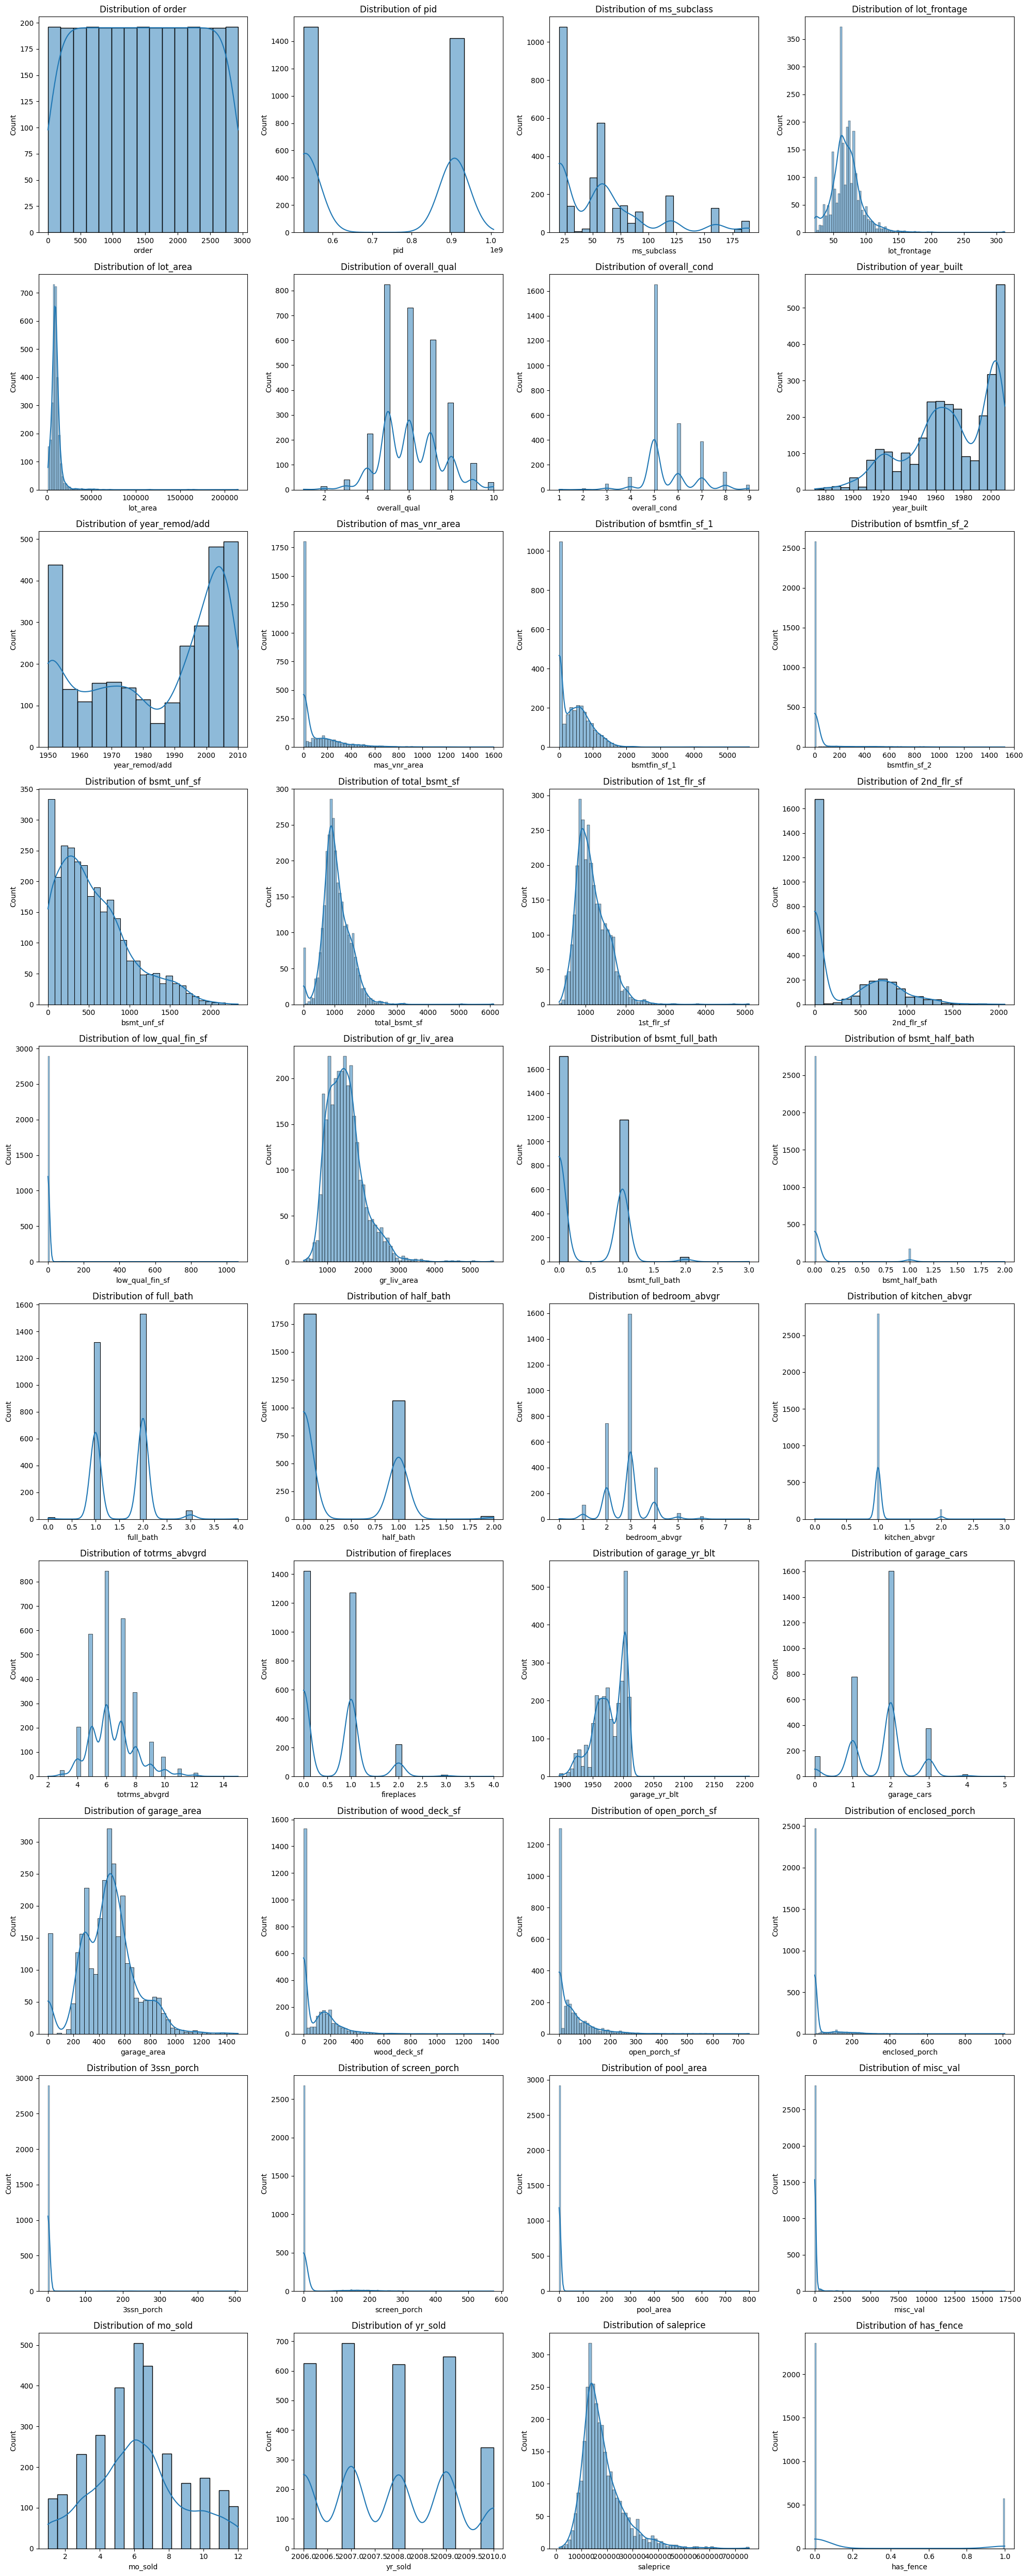

In [40]:
n = len(num_cols)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))
axes = axes.flatten()

for i, feature in enumerate(num_cols):
    sns.histplot(df[feature], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {feature}')

# Hide empty subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

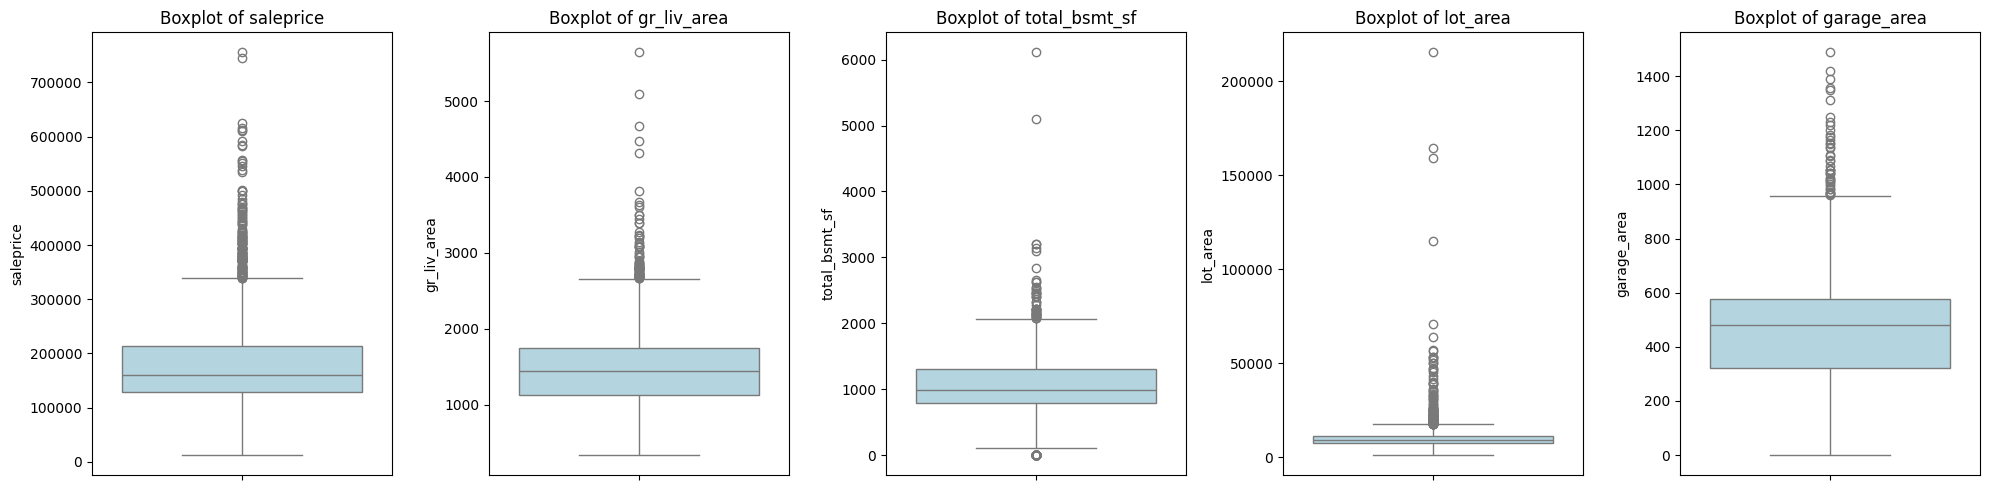

In [41]:
# Boxplots for key numerical features
box_features = ['saleprice', 'gr_liv_area', 'total_bsmt_sf', 'lot_area', 'garage_area']
box_features = [f for f in box_features if f in df.columns]

fig, axes = plt.subplots(1, len(box_features), figsize=(20, 5))
for i, feature in enumerate(box_features):
    sns.boxplot(y=df[feature], ax=axes[i], color='lightblue')
    axes[i].set_title(f'Boxplot of {feature}')
plt.tight_layout()
plt.show()

In [42]:
df.drop(
    columns=[ 'misc_val', '3ssn_porch', 'screen_porch',
             'pool_area', 'enclosed_porch', 'low_qual_fin_sf',
             'bsmt_half_bath', 'bsmtfin_sf_2', 'kitchen_abvgr', 'order', 'pid'],
    inplace=True
)

C:\Users\mohamed zizo\AppData\Local\Temp\ipykernel_32448\964762308.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=[object]).columns.tolist()
C:\Users\mohamed zizo\AppData\Local\Temp\ipykernel_32448\964762308.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=feature, order=order, ax=axes[i], palette='viridis')
C:\Users\mohamed zizo\AppData\Local\Temp\ipykernel_32448\964

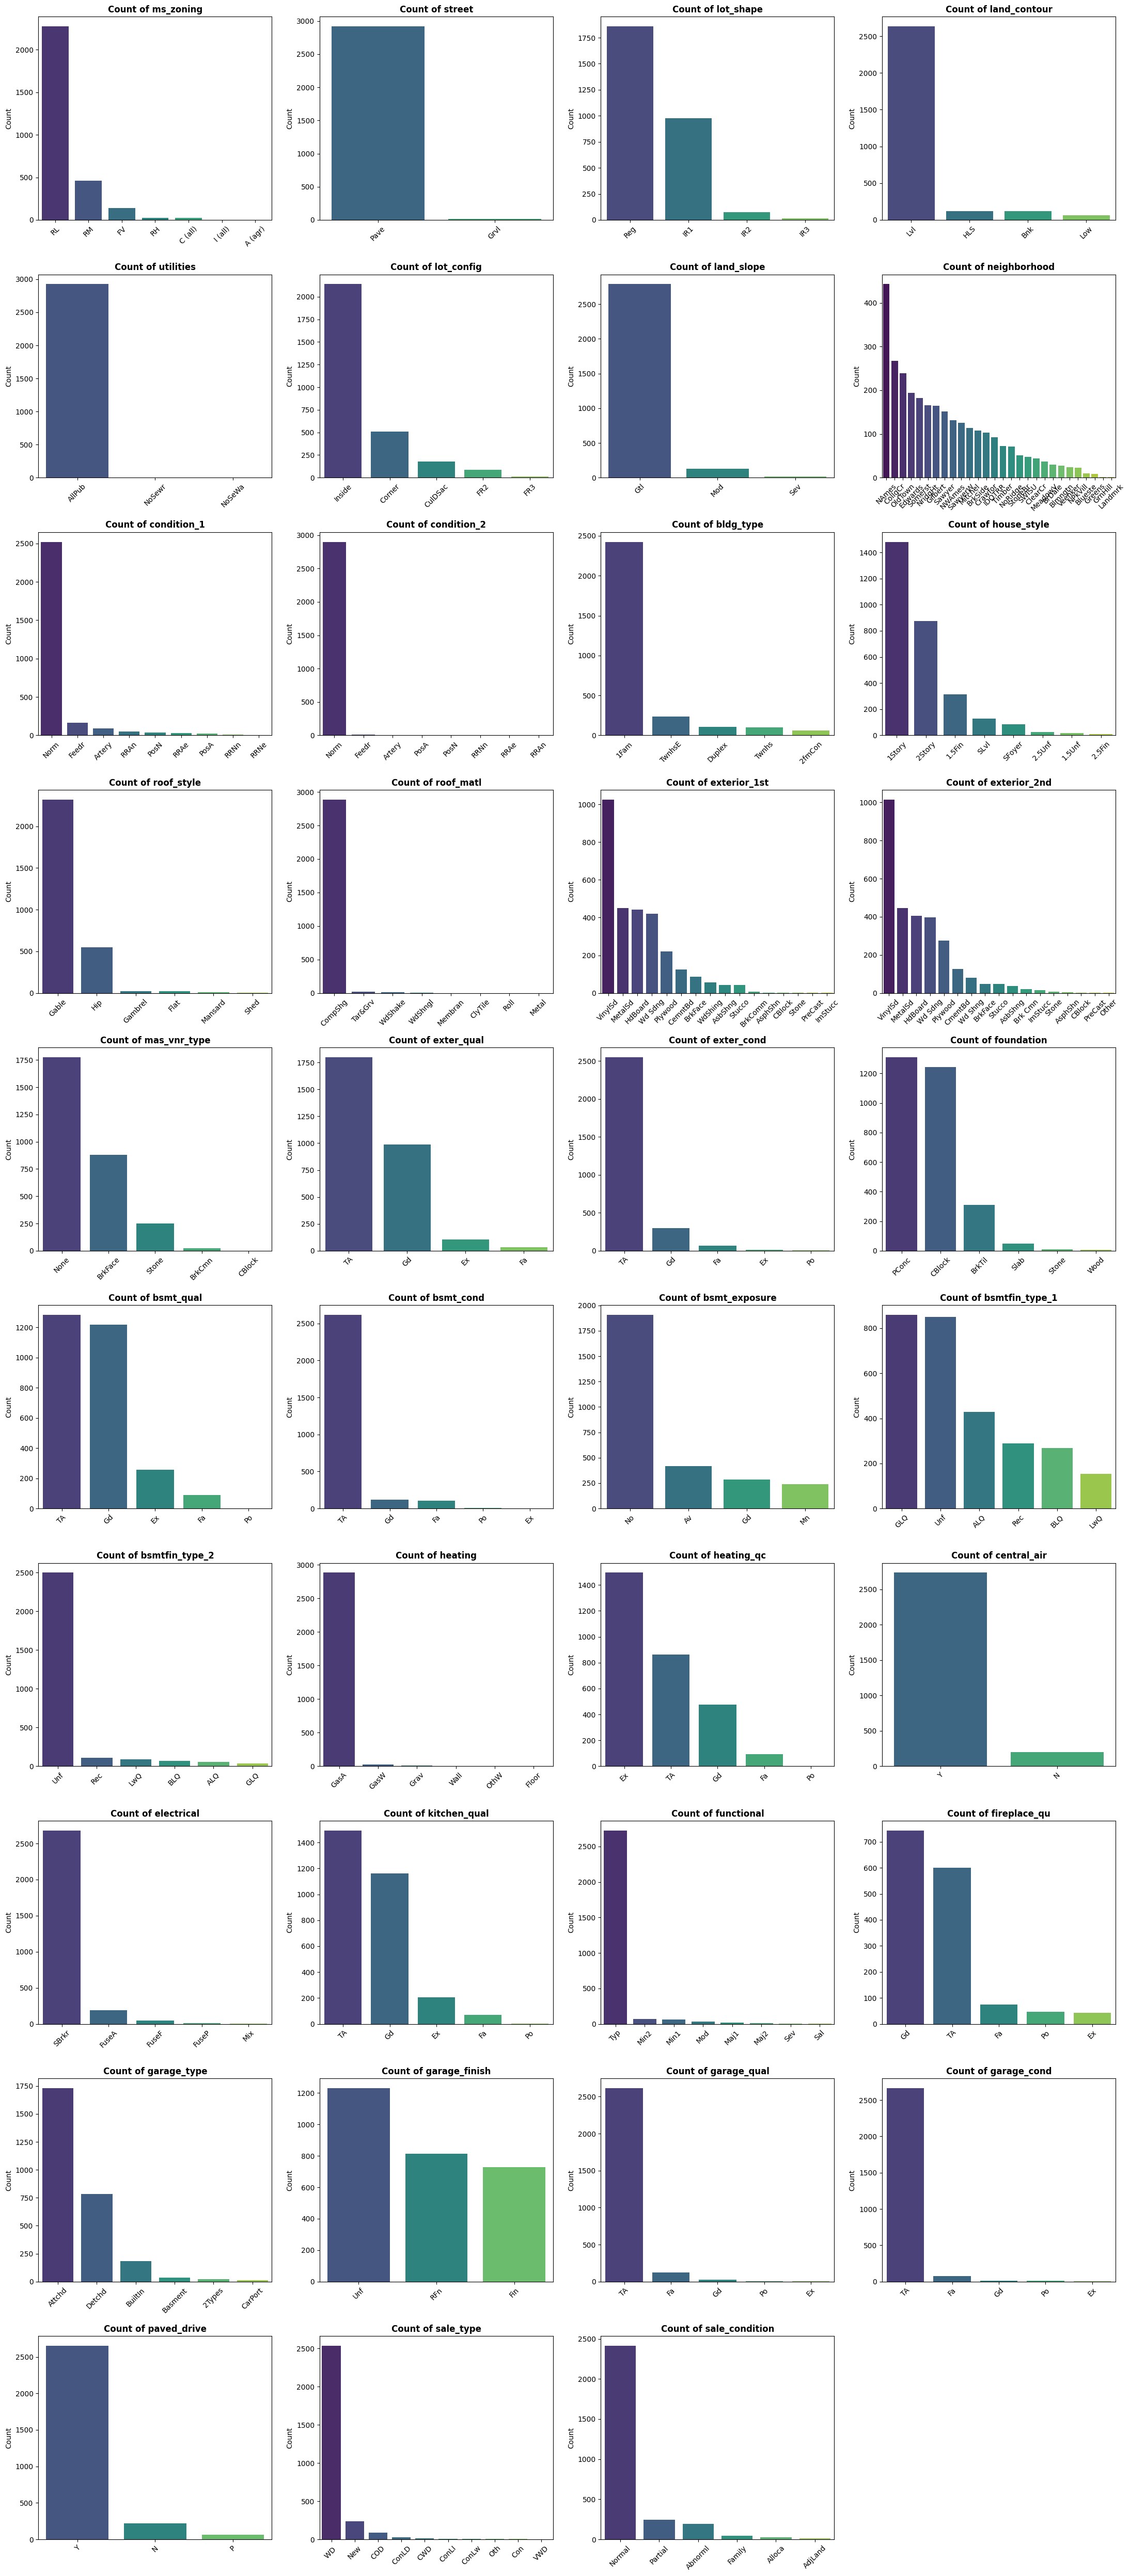

In [43]:
cat_cols = df.select_dtypes(include=[object]).columns.tolist()
n = len(cat_cols)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(22, 5 * rows))
axes = axes.flatten()

for i, feature in enumerate(cat_cols):
    # Sort categories by count (descending)
    order = df[feature].value_counts().index
    
    sns.countplot(data=df, x=feature, order=order, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Count of {feature}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    
    # Rotate labels so they don't overlap (useful for things like neighborhood)
    axes[i].tick_params(axis='x', rotation=45)

# Hide any empty subplot boxes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [44]:
def check_low_variance(df, dominant_threshold=0.95):
    results = []
    
    for col in df.columns:
        top_freq_pct = df[col].value_counts(normalize=True, dropna=False).iloc[0] * 100
        most_common_val = df[col].value_counts(dropna=False).index[0]
        
        variance = df[col].var() if np.issubdtype(df[col].dtype, np.number) else np.nan
        
        if top_freq_pct >= (dominant_threshold * 100):
            results.append({
                'Column': col,
                'Dtype': df[col].dtype,
                'Most Common Value': most_common_val,
                'Dominant %': round(top_freq_pct, 2),
                'Variance': round(variance, 4) if pd.notnull(variance) else 'N/A'
            })
            
    # If no columns exceeded the threshold, return a message safely
    if not results:
        print(f"No columns found where a single value dominates >= {dominant_threshold * 100}%.")
        return pd.DataFrame(columns=['Column', 'Dtype', 'Most Common Value', 'Dominant %', 'Variance'])
            
    report = pd.DataFrame(results).sort_values(by='Dominant %', ascending=False)
    return report.reset_index(drop=True)

In [45]:
#check_low_variance(df[cat_cols], dominant_threshold=0.90)

In [46]:
drop_cols = [
    'utilities', 'street', 'condition_2', 'roof_matl', 
    'heating', 'land_slope', 'garage_cond', 'functional'
]
df.drop(columns=drop_cols, inplace=True, errors='ignore')

In [47]:
# Missing data summary
missing = pd.DataFrame({
    'Count': df.isnull().sum(),
    'Percentage': (df.isnull().mean() * 100).round(2)
})
missing = missing[missing['Count'] > 0].sort_values('Count', ascending=False)
missing

,Count,Percentage
fireplace_qu,1422,48.53
lot_frontage,490,16.72
garage_yr_blt,159,5.43
garage_finish,159,5.43
garage_qual,159,5.43
garage_type,157,5.36
bsmt_exposure,83,2.83
bsmtfin_type_2,81,2.76
bsmt_qual,80,2.73
bsmtfin_type_1,80,2.73


C:\Users\mohamed zizo\AppData\Local\Temp\ipykernel_32448\1583126583.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing['Percentage'], y=missing.index, palette='viridis')


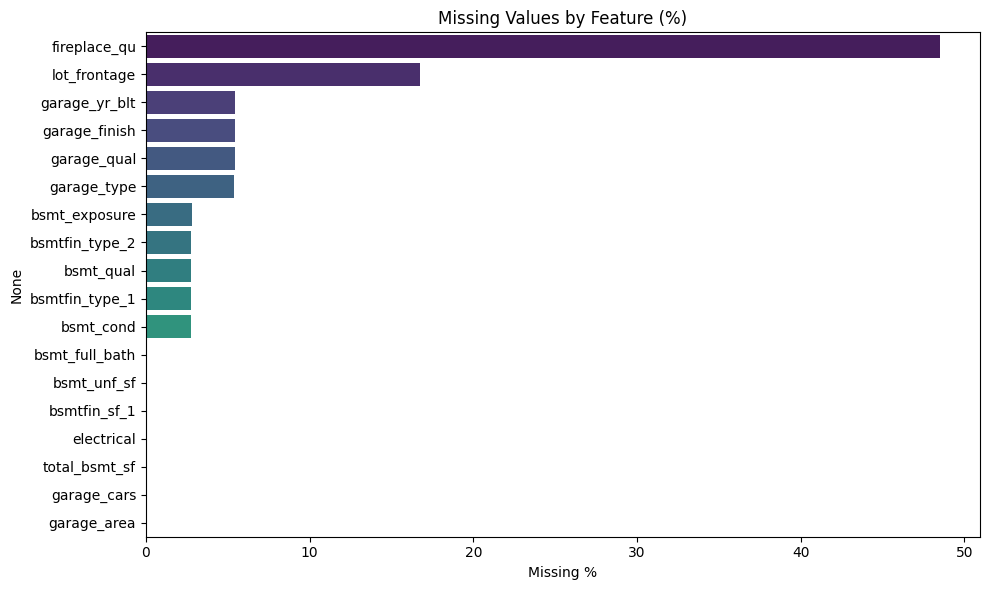

In [48]:
# Visualize missing data
plt.figure(figsize=(10, 6))
sns.barplot(x=missing['Percentage'], y=missing.index, palette='viridis')
plt.title('Missing Values by Feature (%)')
plt.xlabel('Missing %')
plt.tight_layout()
plt.show()

### Missing Data Types:
- **MNAR:** garage/basement/fireplace features → NA means house doesn't have it → fill with 'None' or 0
- **MAR:** lot_frontage → depends on neighborhood layout → fill with neighborhood median
- **MCAR:** electrical → 1 random missing value → fill with mode ('SBrkr')

# 3.Imputation and missing handling

In [49]:
df['fireplace_qu'] = df['fireplace_qu'].fillna('None')
df['fireplace_qu'].value_counts()

fireplace_qu
None    1422
Gd       744
TA       600
Fa        75
Po        46
Ex        43
Name: count, dtype: int64

In [50]:
df['garage_finish']=df['garage_finish'].fillna('None')
df['garage_finish'].value_counts()


garage_finish
Unf     1231
RFn      812
Fin      728
None     159
Name: count, dtype: int64

In [51]:
df['garage_qual']=df['garage_qual'].fillna('None')

df['garage_qual'].value_counts()

garage_qual
TA      2615
None     159
Fa       124
Gd        24
Po         5
Ex         3
Name: count, dtype: int64

In [52]:
df['garage_type']=df['garage_type'].fillna('None')
df['garage_type'].value_counts()

garage_type
Attchd     1731
Detchd      782
BuiltIn     186
None        157
Basment      36
2Types       23
CarPort      15
Name: count, dtype: int64

In [53]:
df['garage_cars']=df['garage_cars'].fillna(0)
df['garage_cars'].value_counts()

garage_cars
2.0    1603
1.0     778
3.0     374
0.0     158
4.0      16
5.0       1
Name: count, dtype: int64

In [54]:
df['garage_area']=df['garage_area'].fillna(0)
df['garage_area'].value_counts()

garage_area
0.0      158
576.0     97
440.0     96
484.0     76
240.0     69
        ... 
272.0      1
327.0      1
766.0      1
693.0      1
405.0      1
Name: count, Length: 603, dtype: int64

In [55]:
df['garage_yr_blt']=df['garage_yr_blt'].fillna(0)
df['garage_yr_blt'].value_counts()

garage_yr_blt
0.0       159
2005.0    142
2006.0    115
2007.0    115
2004.0     99
         ... 
1895.0      1
1933.0      1
2207.0      1
1943.0      1
1919.0      1
Name: count, Length: 104, dtype: int64

In [56]:
df['lot_frontage'] = df.groupby('neighborhood')['lot_frontage'].transform(lambda x: x.fillna(x.median()))

In [57]:
df['total_bsmt_sf']=df['total_bsmt_sf'].fillna(0)
df['total_bsmt_sf'].value_counts()

total_bsmt_sf
0.0       80
864.0     74
672.0     29
912.0     26
1040.0    25
          ..
1210.0     1
1309.0     1
1381.0     1
757.0      1
1003.0     1
Name: count, Length: 1058, dtype: int64

In [58]:
df['bsmtfin_sf_1']=df['bsmtfin_sf_1'].fillna(0)
df['bsmtfin_sf_1'].value_counts()

bsmtfin_sf_1
0.0       931
24.0       27
16.0       14
300.0       9
600.0       8
         ... 
149.0       1
1606.0      1
1224.0      1
337.0       1
1071.0      1
Name: count, Length: 995, dtype: int64

In [59]:
df['bsmt_unf_sf']=df['bsmt_unf_sf'].fillna(0)
df['bsmt_unf_sf'].value_counts()

bsmt_unf_sf
0.0       245
384.0      19
728.0      14
672.0      13
600.0      12
         ... 
1686.0      1
129.0       1
45.0        1
1503.0      1
239.0       1
Name: count, Length: 1137, dtype: int64

In [60]:
df['bsmt_full_bath']=df['bsmt_full_bath'].fillna(0)
df['bsmt_full_bath'].value_counts()

bsmt_full_bath
0.0    1709
1.0    1181
2.0      38
3.0       2
Name: count, dtype: int64

In [61]:
df['bsmt_qual']=df['bsmt_qual'].fillna("None")
df['bsmt_qual'].value_counts()

bsmt_qual
TA      1283
Gd      1219
Ex       258
Fa        88
None      80
Po         2
Name: count, dtype: int64

In [62]:
df['bsmt_cond']=df['bsmt_cond'].fillna('None')
df['bsmt_cond'].value_counts()

bsmt_cond
TA      2616
Gd       122
Fa       104
None      80
Po         5
Ex         3
Name: count, dtype: int64

In [63]:
df['bsmt_exposure']=df['bsmt_exposure'].fillna('None')
df['bsmt_exposure'].value_counts()

bsmt_exposure
No      1906
Av       418
Gd       284
Mn       239
None      83
Name: count, dtype: int64

In [64]:
df['bsmtfin_type_1']=df['bsmtfin_type_1'].fillna('None')
df['bsmtfin_type_1'].value_counts()

bsmtfin_type_1
GLQ     859
Unf     851
ALQ     429
Rec     288
BLQ     269
LwQ     154
None     80
Name: count, dtype: int64

In [65]:
df['bsmtfin_type_2']=df['bsmtfin_type_2'].fillna('None')
df['bsmtfin_type_2'].value_counts()

bsmtfin_type_2
Unf     2499
Rec      106
LwQ       89
None      81
BLQ       68
ALQ       53
GLQ       34
Name: count, dtype: int64

In [66]:
df['electrical']= df['electrical'].fillna('SBrkr')
df['electrical'].value_counts()

electrical
SBrkr    2683
FuseA     188
FuseF      50
FuseP       8
Mix         1
Name: count, dtype: int64

In [67]:
df['lot_frontage'] = (
    df.groupby('neighborhood')['lot_frontage']
      .transform(lambda x: x.fillna(x.median()))
      .fillna(df['lot_frontage'].median())
)

In [68]:
# Check remaining columns with null values
null_counts = df.isnull().sum()
null_counts[null_counts > 0].sort_values(ascending=False)

Series([], dtype: int64)

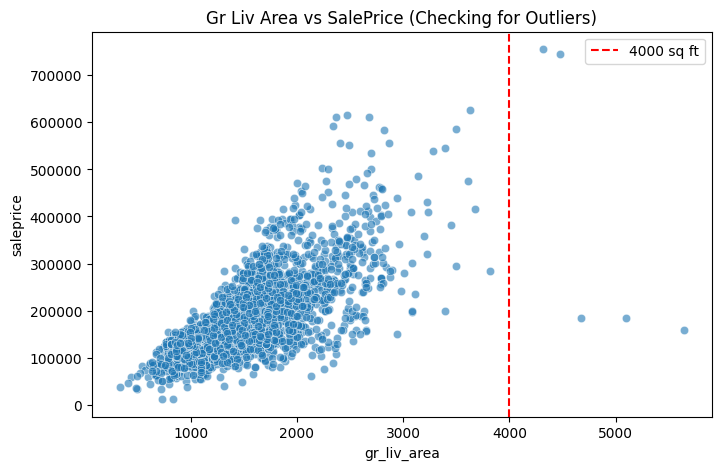

In [69]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['gr_liv_area'], y=df['saleprice'], alpha=0.6)
plt.axvline(x=4000, color='r', linestyle='--', label='4000 sq ft')
plt.title('Gr Liv Area vs SalePrice (Checking for Outliers)')
plt.legend()
plt.show()

In [91]:
def drop_ames_anomalies(data):
    """
    Drops the 3 partial-sale mega-mansions with gr_liv_area > 4000 sq ft
    and saleprice < $300,000 as recommended by the dataset creator.
    """
    initial_rows = len(data)
    mask = (data['gr_liv_area'] > 4000) & (data['saleprice'] < 300000)
    cleaned_data = data[~mask].reset_index(drop=True)
    
    dropped_count = initial_rows - len(cleaned_data)
    print(f" Dropped {dropped_count} anomalous outliers (GrLivArea > 4000 & SalePrice < $300k).")
    return cleaned_data


def clip_outliers_quantile(data, column, lower_q=0.0, upper_q=0.99):
    """
    Caps extreme values in a column using quantile thresholds
    (Winsorization) without dropping the entire row.
    """
    lower_val = data[column].quantile(lower_q)
    upper_val = data[column].quantile(upper_q)
    
    data[column] = data[column].clip(lower=lower_val, upper=upper_val)
    print(f" Clipped '{column}' to range [{lower_val:.1f}, {upper_val:.1f}] ({upper_q*100}th percentile).")
    return data

In [92]:
# 1. Drop the 3 extreme anomalies
df = drop_ames_anomalies(df)

# 2. Clip extreme lot acreage (caps the top 1% largest properties at ~31,600 sq ft)
df = clip_outliers_quantile(df, column='lot_area', lower_q=0.0, upper_q=0.99)

# Verify the new shape
print(f"New DataFrame shape: {df.shape}")

 Dropped 0 anomalous outliers (GrLivArea > 4000 & SalePrice < $300k).
 Clipped 'lot_area' to range [1300.0, 31534.8] (99.0th percentile).
New DataFrame shape: (2927, 58)


# 3.5 Bivariate Analysis & Correlation

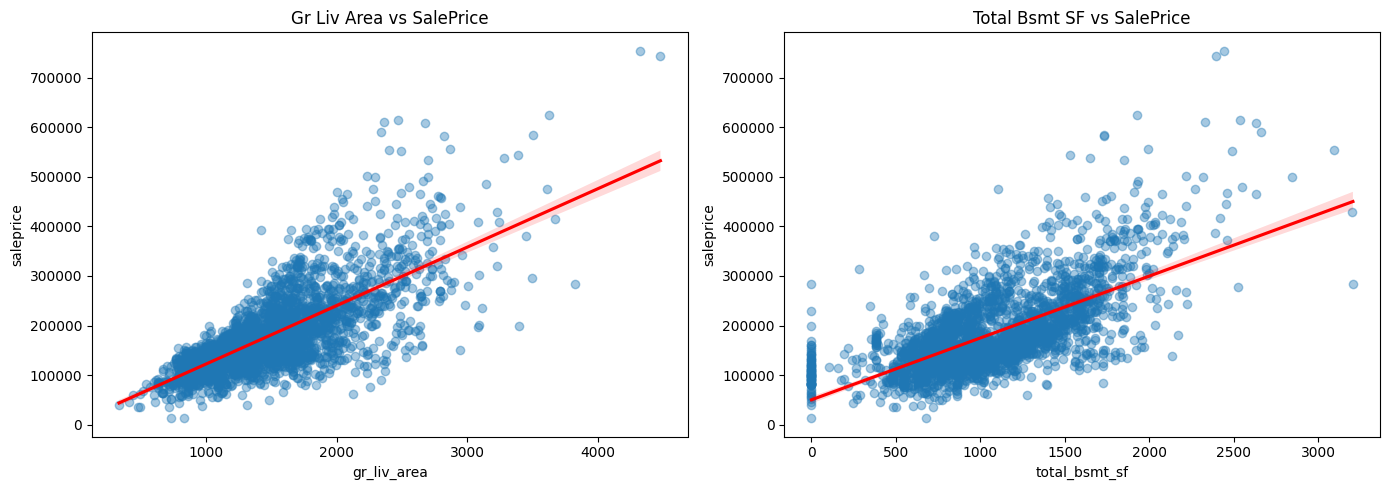

In [72]:
# Numerical vs Numerical
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(data=df, x='gr_liv_area', y='saleprice', ax=ax1,
            scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
ax1.set_title('Gr Liv Area vs SalePrice')

sns.regplot(data=df, x='total_bsmt_sf', y='saleprice', ax=ax2,
            scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
ax2.set_title('Total Bsmt SF vs SalePrice')

plt.tight_layout()
plt.show()

C:\Users\mohamed zizo\AppData\Local\Temp\ipykernel_32448\2820946424.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='overall_qual', y='saleprice', ax=ax1, palette='coolwarm')
C:\Users\mohamed zizo\AppData\Local\Temp\ipykernel_32448\2820946424.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['neighborhood'].isin(top_hoods)], y='neighborhood', x='saleprice',


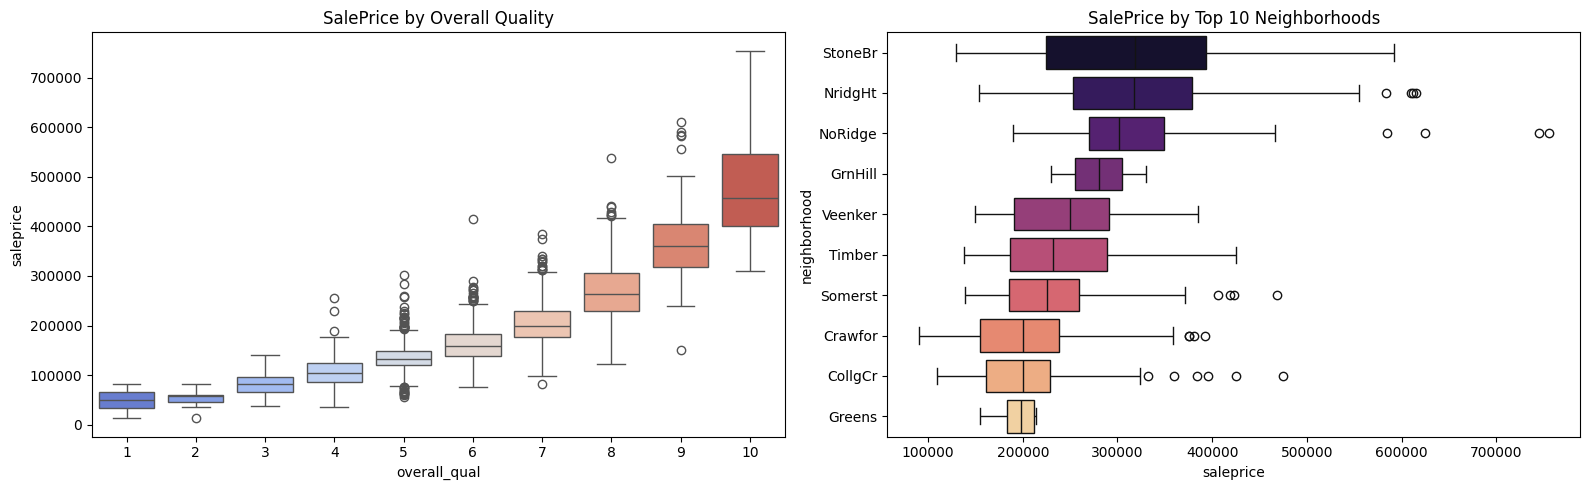

In [73]:
# Numerical vs Categorical
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=df, x='overall_qual', y='saleprice', ax=ax1, palette='coolwarm')
ax1.set_title('SalePrice by Overall Quality')

top_hoods = df.groupby('neighborhood')['saleprice'].median().sort_values(ascending=False).head(10).index
sns.boxplot(data=df[df['neighborhood'].isin(top_hoods)], y='neighborhood', x='saleprice',
            order=top_hoods, ax=ax2, palette='magma')
ax2.set_title('SalePrice by Top 10 Neighborhoods')

plt.tight_layout()
plt.show()

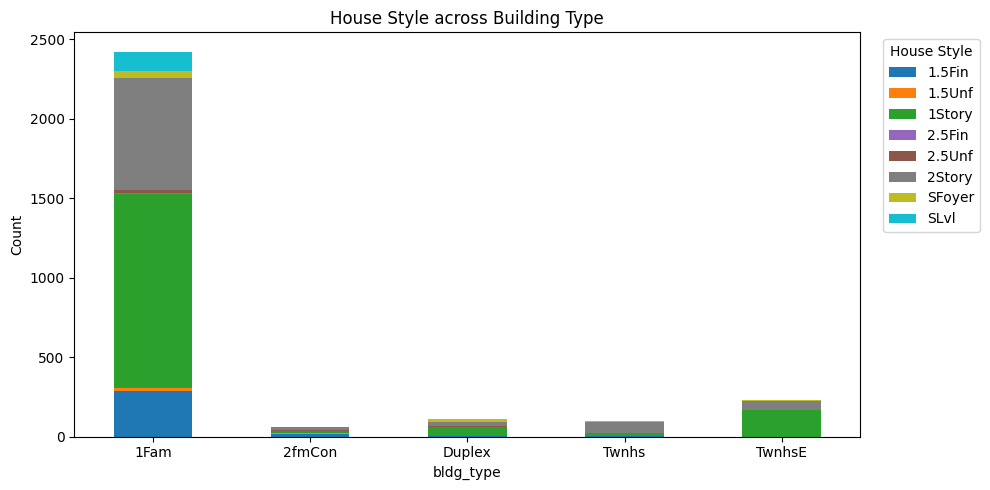

In [74]:
# Categorical vs Categorical
ct = pd.crosstab(df['bldg_type'], df['house_style'])
ct.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab10')
plt.title('House Style across Building Type')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='House Style', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

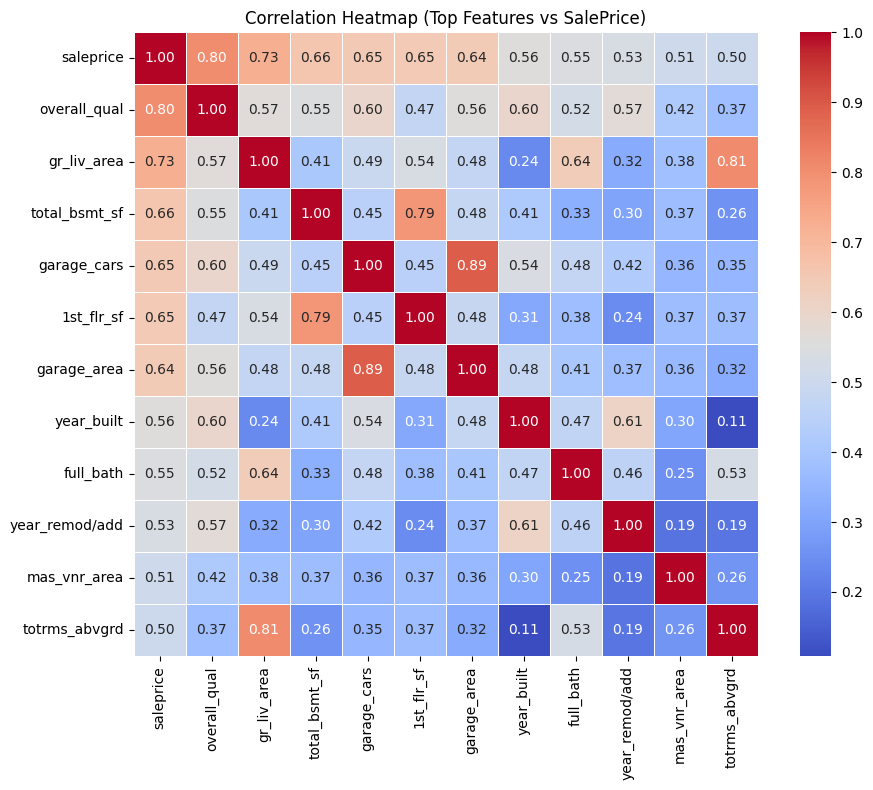

In [75]:
# Correlation Heatmap
num_df = df.select_dtypes(include=[np.number])
top_corr = num_df.corr()['saleprice'].abs().sort_values(ascending=False).head(12).index

plt.figure(figsize=(10, 8))
sns.heatmap(df[top_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Heatmap (Top Features vs SalePrice)')
plt.tight_layout()
plt.show()

# 4.Feature Engineering

In [76]:
# 1. Total Square Footage (combining 1st floor, 2nd floor, and basement)
df['total_sf'] = df['1st_flr_sf'] + df['2nd_flr_sf'] + df['total_bsmt_sf']

# 2. Total Bathrooms (combining full, half, and basement baths)
df['total_baths'] = df['full_bath'] + (0.5 * df['half_bath']) + df['bsmt_full_bath']

# 3. Age of House and Remodel at time of sale
df['house_age'] = df['yr_sold'] - df['year_built']
df['remod_age'] = df['yr_sold'] - df['year_remod/add']

# Prevent negative ages (e.g. if built/remodeled in the same year as sold or data discrepancy)
df['house_age'] = df['house_age'].clip(lower=0)
df['remod_age'] = df['remod_age'].clip(lower=0)

# 4. Remodeled Flag (1 if remodeled, 0 if original condition)
df['is_remodeled'] = (df['year_remod/add'] != df['year_built']).astype(int)

# 5. Total Outdoor Living Area (Porch + Deck)
df['total_porch_sf'] = df['wood_deck_sf'] + df['open_porch_sf']

In [77]:
redundant_cols = [
    '1st_flr_sf', '2nd_flr_sf',             # Captured in total_sf and gr_liv_area
    'half_bath', 'bsmt_full_bath',          # Captured in total_baths
    'year_built', 'year_remod/add',         # Replaced by house_age and remod_age
    'wood_deck_sf', 'open_porch_sf'         # Captured in total_porch_sf
]

df = df.drop(columns=redundant_cols, errors='ignore')

print(f"Current columns count: {df.shape[1]}")

Current columns count: 58


In [78]:
new_features = ['total_sf', 'gr_liv_area', 'overall_qual', 'total_baths', 'house_age', 'saleprice']
correlations = df[new_features].corr()['saleprice'].sort_values(ascending=False)

print("Correlation with SalePrice:")
print(correlations)

Correlation with SalePrice:
saleprice       1.000000
total_sf        0.832384
overall_qual    0.802592
gr_liv_area     0.727122
total_baths     0.637054
house_age      -0.559407
Name: saleprice, dtype: float64


# 5.Modeling

In [79]:
y = np.log1p(df['saleprice'])

X = df.drop(columns=['saleprice'])

In [80]:
quality_map = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}

ordinal_cols = ['exter_qual', 'bsmt_qual', 'kitchen_qual', 'fireplace_qu', 'garage_qual', 'heating_qc']

for col in ordinal_cols:
    if col in X.columns:
        X[col] = X[col].map(quality_map).fillna(0).astype(int)

In [81]:
# Train-test split FIRST (before encoding to avoid data leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [93]:
# One-hot encode train and test separately
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

# Align columns so test has same features as train
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)



In [83]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [84]:
lasso = LassoCV(cv=5, random_state=42, max_iter=20000)

lasso.fit(X_train_scaled, y_train)

,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"n_alphas n_alphas: int, default=100Number of alphas along the regularization path... deprecated:: 1.7 `n_alphas` was deprecated in 1.7 and will be removed in 1.9. Use `alphas` instead.",'deprecated'
,"alphas alphas: array-like or int, default=NoneValues of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`... deprecated:: 1.7 `alphas=None` was deprecated in 1.7 and will be removed in 1.9, at which point the default value will be set to 100.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",20000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: bool or int, default=FalseAmount of verbosity.",False
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [94]:
y_pred = lasso.predict(X_test_scaled)
test_r2 = r2_score(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Convert back to dollars for MAE
y_pred_lasso_dollars = np.expm1(y_pred)
y_test_dollars = np.expm1(y_test)
lasso_mae = mean_absolute_error(y_test_dollars, y_pred_lasso_dollars)

print(f"Test R\u00b2 Score:     {test_r2:.4f}")
print(f"Test RMSE (log):  {test_rmse:.4f}")


Test R² Score:     0.9495
Test RMSE (log):  0.0952


In [95]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_log = xgb_model.predict(X_test)

xgb_r2 = r2_score(y_test, y_pred_log)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_log))

y_pred_xgb_dollars = np.expm1(y_pred_log)
xgb_mae = mean_absolute_error(y_test_dollars, y_pred_xgb_dollars)

print(f"XGBoost Test R\u00b2 Score:   {xgb_r2:.4f}")
print(f"XGBoost Test RMSE (log): {xgb_rmse:.4f}")


XGBoost Test R² Score:   0.9490
XGBoost Test RMSE (log): 0.0958


# 6.Model Comparison & Feature Importance

In [96]:
# Side-by-side comparison
comparison = pd.DataFrame({
    'Model': ['LassoCV', 'XGBoost'],
    'R2': [test_r2, xgb_r2],
    'RMSE (log)': [test_rmse, xgb_rmse],
})
comparison

,Model,R2,RMSE (log)
0,LassoCV,0.949506,0.095236
1,XGBoost,0.948956,0.095752


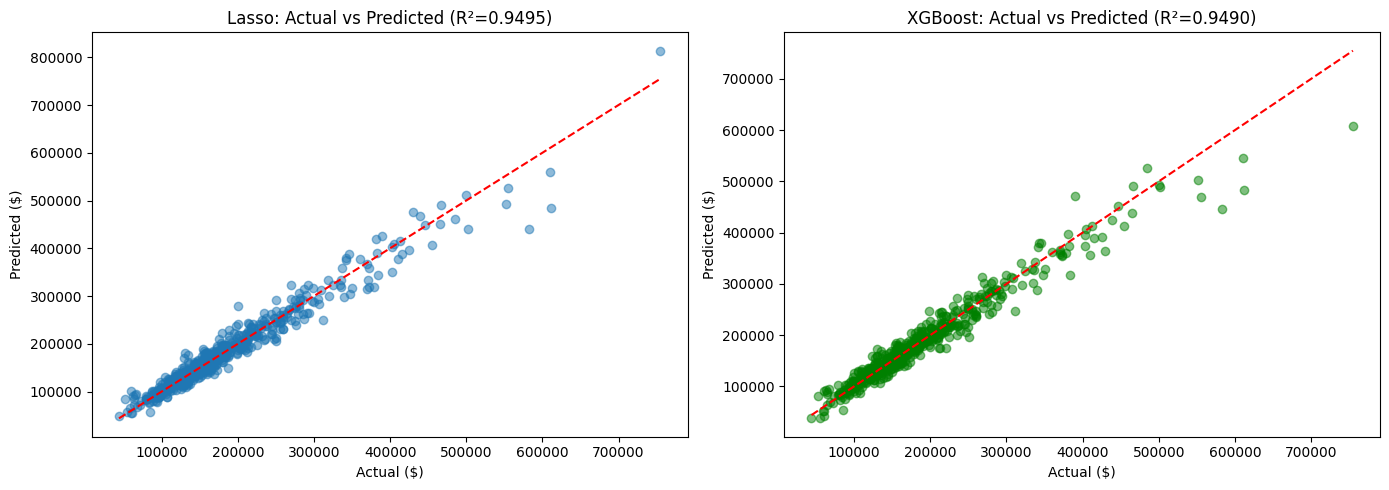

In [97]:
# Actual vs Predicted
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(y_test_dollars, y_pred_lasso_dollars, alpha=0.5)
ax1.plot([y_test_dollars.min(), y_test_dollars.max()],
         [y_test_dollars.min(), y_test_dollars.max()], 'r--')
ax1.set_title(f'Lasso: Actual vs Predicted (R\u00b2={test_r2:.4f})')
ax1.set_xlabel('Actual ($)')
ax1.set_ylabel('Predicted ($)')

ax2.scatter(y_test_dollars, y_pred_xgb_dollars, alpha=0.5, color='green')
ax2.plot([y_test_dollars.min(), y_test_dollars.max()],
         [y_test_dollars.min(), y_test_dollars.max()], 'r--')
ax2.set_title(f'XGBoost: Actual vs Predicted (R\u00b2={xgb_r2:.4f})')
ax2.set_xlabel('Actual ($)')
ax2.set_ylabel('Predicted ($)')

plt.tight_layout()
plt.show()

C:\Users\mohamed zizo\AppData\Local\Temp\ipykernel_32448\2440638345.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15.values, y=top15.index, palette='viridis')


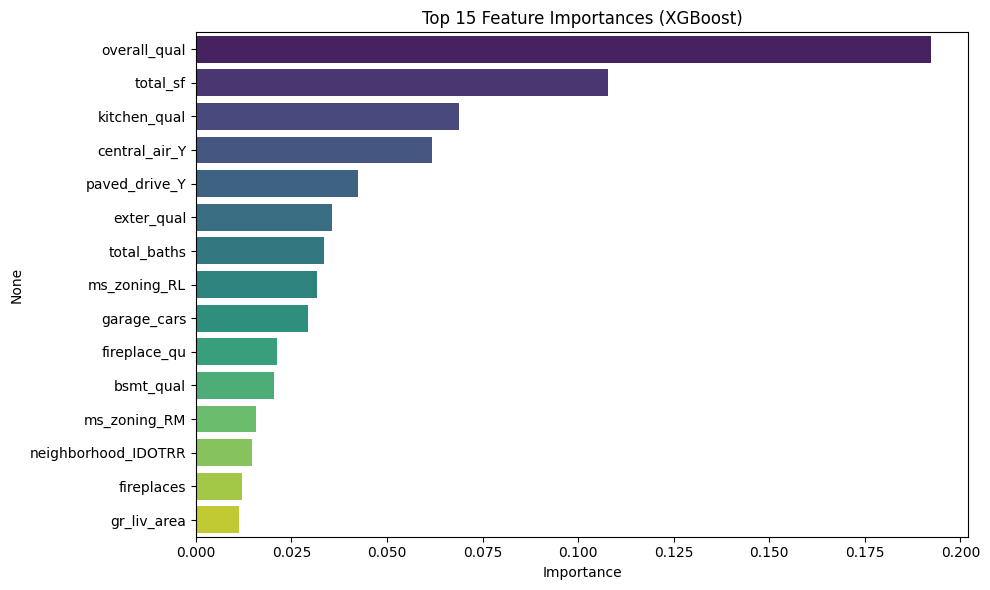

In [89]:
# Top 15 Feature Importances (XGBoost)
importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top15.values, y=top15.index, palette='viridis')
plt.title('Top 15 Feature Importances (XGBoost)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

C:\Users\mohamed zizo\AppData\Local\Temp\ipykernel_32448\32218750.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_all.values, y=top_all.index, palette=colors)


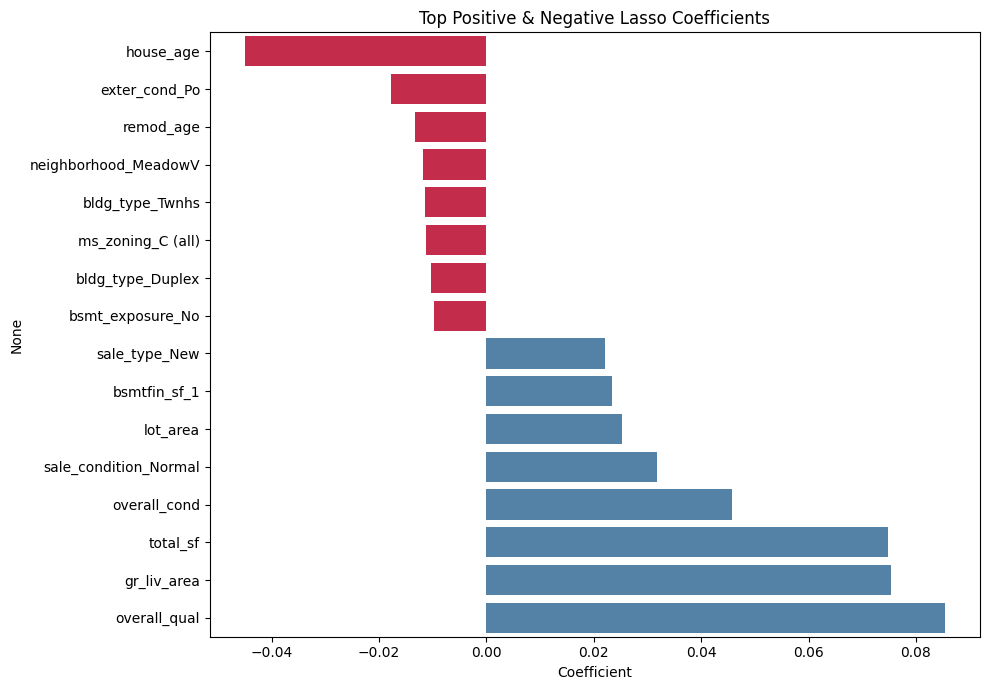

In [90]:
# Top Lasso Coefficients
lasso_coefs = pd.Series(lasso.coef_, index=X_train.columns)
top_pos = lasso_coefs.sort_values(ascending=False).head(8)
top_neg = lasso_coefs.sort_values().head(8)
top_all = pd.concat([top_pos, top_neg]).sort_values()

plt.figure(figsize=(10, 7))
colors = ['crimson' if c < 0 else 'steelblue' for c in top_all.values]
sns.barplot(x=top_all.values, y=top_all.index, palette=colors)
plt.title('Top Positive & Negative Lasso Coefficients')
plt.xlabel('Coefficient')
plt.tight_layout()
plt.show()